In [ ]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_ind

In [ ]:
gct_file = "GTEx_Analysis_2017-06-05_v8_RNASeQCv1.1.9_gene_tpm.gct"

# Print first 5 lines to understand the structure
with open(gct_file, 'rt') as f:
    for _ in range(5):
        print(f.readline())

# Now read the file, skipping the first two metadata lines
expression_df = pd.read_csv(gct_file, sep='\t', skiprows=2)

# Preview the dataframe
expression_df.head()


#1.2

56200	17382

Name	Description	GTEX-1117F-0226-SM-5GZZ7	GTEX-1117F-0426-SM-5EGHI	GTEX-1117F-0526-SM-5EGHJ	GTEX-1117F-0626-SM-5N9CS	GTEX-1117F-0726-SM-5GIEN	GTEX-1117F-1326-SM-5EGHH	GTEX-1117F-2426-SM-5EGGH	GTEX-1117F-2526-SM-5GZY6	GTEX-1117F-2826-SM-5GZXL	GTEX-1117F-2926-SM-5GZYI	GTEX-1117F-3026-SM-5GZYU	GTEX-1117F-3226-SM-5N9CT	GTEX-111CU-0126-SM-5GZWZ	GTEX-111CU-0226-SM-5GZXC	GTEX-111CU-0326-SM-5GZXO	GTEX-111CU-0426-SM-5GZY1	GTEX-111CU-0526-SM-5EGHK	GTEX-111CU-0626-SM-5EGHL	GTEX-111CU-0726-SM-5GZYD	GTEX-111CU-0826-SM-5EGIJ	GTEX-111CU-0926-SM-5EGIK	GTEX-111CU-1026-SM-5EGIL	GTEX-111CU-1126-SM-5EGIM	GTEX-111CU-1226-SM-5EGIN	GTEX-111CU-1326-SM-5NQ8L	GTEX-111CU-1426-SM-5GZYP	GTEX-111CU-1526-SM-5N9FS	GTEX-111CU-1726-SM-5EGHM	GTEX-111CU-1826-SM-5GZYN	GTEX-111CU-2026-SM-5GZZC	GTEX-111CU-2226-SM-5N9G5	GTEX-111FC-0126-SM-5N9DL	GTEX-111FC-0226-SM-5N9B8	GTEX-111FC-0326-SM-5GZZ1	GTEX-111FC-0426-SM-5N9CV	GTEX-111FC-0526-SM-5GZZ8	GTEX-111FC-0626-SM-5N9CU	GTEX-111FC-0826-SM-5GZWO	GTEX-111FC-102

,Name,Description,GTEX-1117F-0226-SM-5GZZ7,GTEX-1117F-0426-SM-5EGHI,GTEX-1117F-0526-SM-5EGHJ,GTEX-1117F-0626-SM-5N9CS,GTEX-1117F-0726-SM-5GIEN,GTEX-1117F-1326-SM-5EGHH,GTEX-1117F-2426-SM-5EGGH,GTEX-1117F-2526-SM-5GZY6,...,GTEX-ZZPU-1126-SM-5N9CW,GTEX-ZZPU-1226-SM-5N9CK,GTEX-ZZPU-1326-SM-5GZWS,GTEX-ZZPU-1426-SM-5GZZ6,GTEX-ZZPU-1826-SM-5E43L,GTEX-ZZPU-2126-SM-5EGIU,GTEX-ZZPU-2226-SM-5EGIV,GTEX-ZZPU-2426-SM-5E44I,GTEX-ZZPU-2626-SM-5E45Y,GTEX-ZZPU-2726-SM-5NQ8O
0,ENSG00000223972.5,DDX11L1,0.00000,0.000,0.000,0.00000,0.000,0.000,0.00,0.00000,...,0.00000,0.03629,0.00000,0.00,0.00000,0.0000,0.000,0.00000,0.01965,0.02522
1,ENSG00000227232.5,WASH7P,8.76400,3.861,7.349,11.07000,3.306,5.389,11.99,16.95000,...,1.60600,2.26800,5.38600,2.31,2.45600,4.0230,1.922,2.85700,0.86960,2.16700
2,ENSG00000278267.1,MIR6859-1,0.00000,0.000,1.004,0.00000,0.000,0.000,0.00,0.00000,...,0.00000,0.00000,0.00000,0.00,0.00000,0.0000,0.000,0.00000,0.00000,0.00000
3,ENSG00000243485.5,MIR1302-2HG,0.07187,0.000,0.000,0.06761,0.000,0.000,0.00,0.00000,...,0.00000,0.00000,0.06073,0.00,0.08464,0.1435,0.000,0.05216,0.00000,0.00000
4,ENSG00000237613.2,FAM138A,0.00000,0.000,0.000,0.00000,0.000,0.000,0.00,0.03904,...,0.02429,0.00000,0.00000,0.00,0.00000,0.0000,0.000,0.00000,0.00000,0.00000


In [ ]:
# Load sample attributes (tissue info)
sample_attributes = pd.read_csv("GTEx_Analysis_v8_Annotations_SampleAttributesDS.txt", sep="\t")

# Load subject phenotypes (sex info)
subject_phenotypes = pd.read_csv("GTEX_Analysis_v8_Annotations_SubjectPhenotypesDS.txt", sep="\t")

# Add subject IDs (first 10 characters of sample ID)
sample_attributes['SUBJID'] = sample_attributes['SAMPID'].str[:10]

# Merge sample info with subject phenotypes
merged_metadata = sample_attributes.merge(
    subject_phenotypes[['SUBJID', 'SEX']],
    on='SUBJID'
)

# Convert numeric SEX codes to labels
merged_metadata['SEX'] = merged_metadata['SEX'].map({1: 'Male', 2: 'Female'})

merged_metadata.head()

,SAMPID,SMATSSCR,SMCENTER,SMPTHNTS,SMRIN,SMTS,SMTSD,SMUBRID,SMTSISCH,SMTSPAX,...,SMBSMMRT,SME1SNSE,SME1PCTS,SMRRNART,SME1MPRT,SMNUM5CD,SMDPMPRT,SME2PCTS,SUBJID,SEX
0,GTEX-1117F-0003-SM-58Q7G,NaN,B1,NaN,NaN,Blood,Whole Blood,0013756,1188.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTEX-1117F,Female
1,GTEX-1117F-0003-SM-5DWSB,NaN,B1,NaN,NaN,Blood,Whole Blood,0013756,1188.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTEX-1117F,Female
2,GTEX-1117F-0003-SM-6WBT7,NaN,B1,NaN,NaN,Blood,Whole Blood,0013756,1188.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTEX-1117F,Female
3,GTEX-1117F-0011-R10a-SM-AHZ7F,NaN,"B1, A1",NaN,NaN,Brain,Brain - Frontal Cortex (BA9),0009834,1193.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTEX-1117F,Female
4,GTEX-1117F-0011-R10b-SM-CYKQ8,NaN,"B1, A1",NaN,7.2,Brain,Brain - Frontal Cortex (BA9),0009834,1193.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GTEX-1117F,Female


In [ ]:
# Keep only skeletal muscle
muscle_samples = merged_metadata[merged_metadata['SMTSD'] == "Muscle - Skeletal"]

print("Male vs Female skeletal muscle samples:")
print(muscle_samples['SEX'].value_counts())

Male vs Female skeletal muscle samples:
SEX
Male      510
Female    232
Name: count, dtype: int64


/var/folders/rl/5n7w7fwj03372wr5d345wb840000gn/T/ipykernel_15089/933146219.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Sex', y='Count', data=sex_counts, palette='pastel')


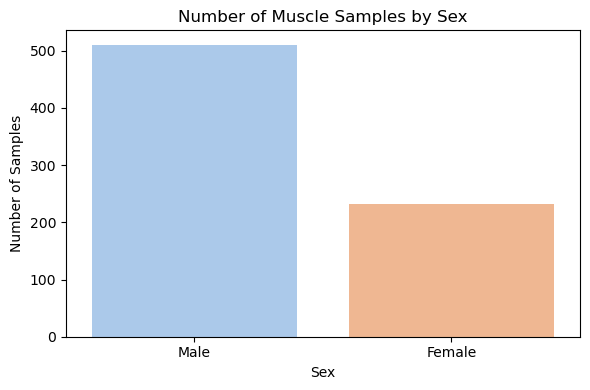

In [ ]:
sex_counts = muscle_samples['SEX'].value_counts().reset_index()
sex_counts.columns = ['Sex', 'Count']

plt.figure(figsize=(6, 4))
sns.barplot(x='Sex', y='Count', data=sex_counts, palette='pastel')
plt.title('Number of Muscle Samples by Sex')
plt.ylabel('Number of Samples')
plt.xlabel('Sex')
plt.tight_layout()
plt.show()

In [ ]:
# Find the overlap between metadata sample IDs and expression_df columns
sample_ids = [s for s in muscle_samples['SAMPID'].tolist() if s in expression_df.columns]

print(f"Total muscle samples in metadata: {len(muscle_samples)}")
print(f"Samples matched in expression data: {len(sample_ids)}")

# Subset expression data to these matched samples
muscle_expression = expression_df[['Name', 'Description'] + sample_ids]

# Set index to gene ID
muscle_expression.set_index("Name", inplace=True)

muscle_expression.head()

Total muscle samples in metadata: 742
Samples matched in expression data: 569


,Description,GTEX-1117F-0426-SM-5EGHI,GTEX-111CU-2026-SM-5GZZC,GTEX-111FC-0326-SM-5GZZ1,GTEX-111VG-2626-SM-5GZY2,GTEX-111YS-2326-SM-5987L,GTEX-1122O-2426-SM-5GIDN,GTEX-1128S-2426-SM-5H11B,GTEX-113JC-2726-SM-5EGIS,GTEX-117XS-2526-SM-5H11G,...,GTEX-1RAZR-0326-SM-EWRNM,GTEX-1RB15-2226-SM-DTXFZ,GTEX-1RQEC-0126-SM-E9J2H,GTEX-1RQED-0426-SM-E6CJP,GTEX-1S5VW-0526-SM-E6CHL,GTEX-1S5ZA-0526-SM-EWRO1,GTEX-1S82P-0326-SM-E9TIR,GTEX-1S82U-1426-SM-E6CJL,GTEX-1S82Y-2226-SM-EWRNV,GTEX-1S83E-2126-SM-EWRO6
Name,,,,,,,,,,,,,,,,,,,,,
ENSG00000223972.5,DDX11L1,0.000,0.000,0.01768,0.00000,0.00000,0.00000,0.000,0.00000,0.00000,...,0.00000,0.00000,0.0000,0.01068,0.00000,0.01232,0.0000,0.0000,0.00000,0.00000
ENSG00000227232.5,WASH7P,3.861,1.036,1.19700,0.46470,0.85420,2.23600,1.222,0.99900,0.86050,...,0.99190,1.79800,0.6288,0.80620,1.91300,1.78000,2.2830,0.9897,0.97980,1.45800
ENSG00000278267.1,MIR6859-1,0.000,0.000,0.00000,0.00000,0.00000,0.00000,0.000,0.00000,0.00000,...,0.00000,0.00000,0.0000,0.00000,0.00000,0.00000,0.0000,0.0000,0.00000,0.00000
ENSG00000243485.5,MIR1302-2HG,0.000,0.000,0.00000,0.00000,0.00000,0.00000,0.000,0.04643,0.03473,...,0.02084,0.03536,0.0000,0.00000,0.02158,0.02459,0.1141,0.0000,0.02782,0.02457
ENSG00000237613.2,FAM138A,0.000,0.000,0.02508,0.02664,0.06418,0.03807,0.000,0.00000,0.00000,...,0.00000,0.00000,0.0000,0.01514,0.00000,0.00000,0.0000,0.0000,0.01977,0.00000


In [ ]:
# Restrict male/female IDs to those actually in expression matrix
male_ids = [s for s in muscle_samples[muscle_samples['SEX'] == "Male"]["SAMPID"] if s in muscle_expression.columns]
female_ids = [s for s in muscle_samples[muscle_samples['SEX'] == "Female"]["SAMPID"] if s in muscle_expression.columns]

print(f"Male samples (metadata): {len(muscle_samples[muscle_samples['SEX']=='Male'])}, matched in expr: {len(male_ids)}")
print(f"Female samples (metadata): {len(muscle_samples[muscle_samples['SEX']=='Female'])}, matched in expr: {len(female_ids)}")

# Split expression matrix
male_expr = muscle_expression[male_ids]
female_expr = muscle_expression[female_ids]

male_expr.shape, female_expr.shape

Male samples (metadata): 510, matched in expr: 398
Female samples (metadata): 232, matched in expr: 171


((56200, 398), (56200, 171))

In [ ]:
results = []

for gene in muscle_expression.index:
    male_vals = male_expr.loc[gene].dropna()
    female_vals = female_expr.loc[gene].dropna()
    
    stat, pval = ttest_ind(male_vals, female_vals, equal_var=False)
    
    results.append([
        gene,
        muscle_expression.loc[gene, "Description"],
        male_vals.mean(),
        female_vals.mean(),
        stat,
        pval
    ])

results_df = pd.DataFrame(results, columns=["GeneID", "GeneName", "Male_Mean", "Female_Mean", "t_stat", "pval"])
results_df.head()

,GeneID,GeneName,Male_Mean,Female_Mean,t_stat,pval
0,ENSG00000223972.5,DDX11L1,0.008418,0.007275,0.833137,0.405355
1,ENSG00000227232.5,WASH7P,1.571595,1.707923,-1.421218,0.156416
2,ENSG00000278267.1,MIR6859-1,0.013707,0.004427,1.453337,0.146693
3,ENSG00000243485.5,MIR1302-2HG,0.021904,0.024408,-0.547687,0.584204
4,ENSG00000237613.2,FAM138A,0.009012,0.007807,0.699568,0.484679


In [ ]:
# Bonferroni correction
n_tests = len(results_df)
results_df["adj_pval"] = (results_df["pval"] * n_tests).clip(upper=1.0)

# Sort by significance
results_df.sort_values("adj_pval", inplace=True)

# Top 10 genes
top10 = results_df.head(10)
top10

,GeneID,GeneName,Male_Mean,Female_Mean,t_stat,pval,adj_pval
55946,ENSG00000198692.9,EIF1AY,25.209070,0.022369,80.288144,1.466980e-247,8.244425e-243
55641,ENSG00000129824.15,RPS4Y1,131.933291,0.255953,69.283093,7.572397e-224,4.255687e-219
55939,ENSG00000012817.15,KDM5D,18.904716,0.055681,56.403648,1.143601e-191,6.427039e-187
55823,ENSG00000114374.12,USP9Y,4.949967,0.012714,51.822934,8.349010e-179,4.692144e-174
55830,ENSG00000183878.15,UTY,4.864324,0.008929,47.761899,1.146264e-166,6.442002e-162
55645,ENSG00000067646.11,ZFY,3.768221,0.008140,47.655366,2.367463e-166,1.330514e-161
55825,ENSG00000067048.16,DDX3Y,19.193995,0.058870,46.275852,4.742295e-162,2.665170e-157
55936,ENSG00000131002.11,TXLNGY,4.824028,0.016571,41.837617,1.274457e-147,7.162446e-143
55929,ENSG00000176728.7,TTTY14,2.882595,0.003870,41.735230,2.825941e-147,1.588179e-142
55938,ENSG00000260197.1,RP11-424G14.1,2.518397,0.005770,37.901195,5.325692e-134,2.993039e-129


/var/folders/rl/5n7w7fwj03372wr5d345wb840000gn/T/ipykernel_15089/3285508892.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="GeneName", y="t_stat", data=top10, palette="coolwarm")


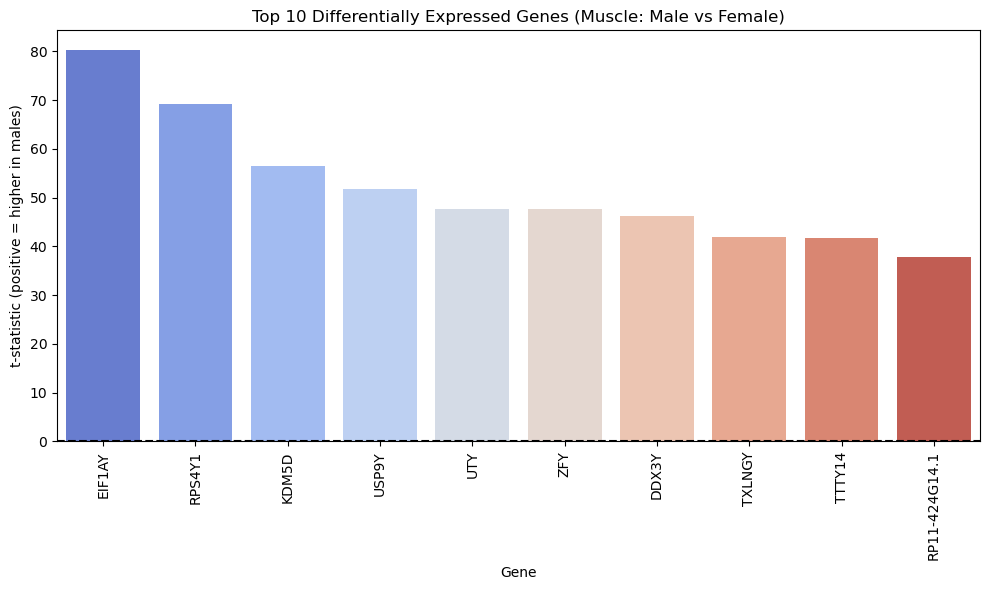

In [ ]:
from matplotlib.patches import Patch


plt.figure(figsize=(10,6))
sns.barplot(x="GeneName", y="t_stat", data=top10, palette="coolwarm")
plt.xticks(rotation=90)
plt.axhline(0, color="black", linestyle="--")
plt.title("Top 10 Differentially Expressed Genes (Muscle: Male vs Female)")
plt.ylabel("t-statistic (positive = higher in males)")
plt.xlabel("Gene")
plt.tight_layout()

plt.show()

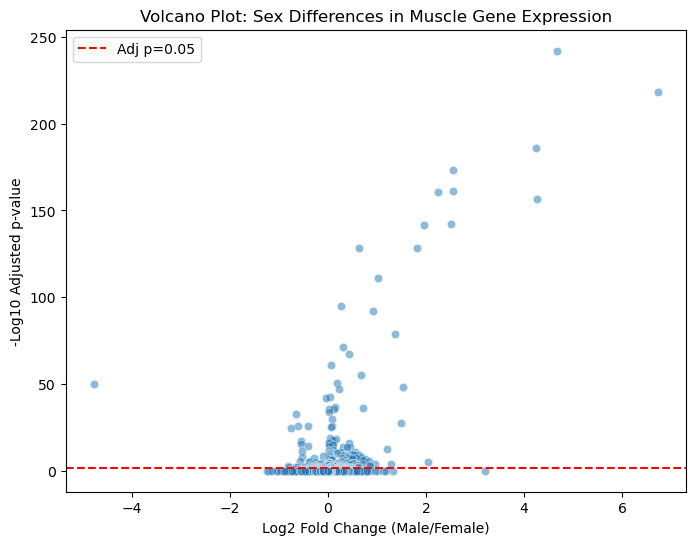

In [ ]:
# Compute log2 fold change
results_df["log2FC"] = np.log2((results_df["Male_Mean"]+1) / (results_df["Female_Mean"]+1))

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=results_df,
    x="log2FC",
    y=-np.log10(results_df["adj_pval"]),
    alpha=0.5
)

plt.axhline(-np.log10(0.05), color="red", linestyle="--", label="Adj p=0.05")
plt.xlabel("Log2 Fold Change (Male/Female)")
plt.ylabel("-Log10 Adjusted p-value")
plt.title("Volcano Plot: Sex Differences in Muscle Gene Expression")
plt.legend()
plt.show()

In [ ]:
results_df.to_csv("muscle_male_vs_female_results.csv", index=False)